# Cierre — Corrección en carreteras de alto tránsito y valor del modelo sin aforos
**Equipo 20 · Proyecto ML–SEDP (Green Stops, corredor CDMX–Acapulco)**

Este notebook atiende los comentarios del asesor al Avance 5:

1. *"El modelo todavía se queda corto en las carreteras con más tráfico […] vale la pena intentar corregirlo."* → Secciones 1 y 2.
2. *"Dejen claro que su valor está en los corredores sin aforos."* → Sección 3.
3. *"Agreguen la sección de contribución individual."* → Sección 6.

Se conserva la **tabla v2** y la validación espacial del Avance 5 (15 regiones contiguas, 5 pliegues y purga de 40 km). La tabla maestra tiene **1,075 registros**: **703 de entrenamiento**, **23 del corredor de prueba** y **349 purgados**. Primero se presentan el diagnóstico y las correcciones ya realizadas al Voting (Ridge, Elastic Net, SVR y Gradient Boosting). El único candidato nuevo que se incorpora al cierre es el **ensamble LightGBM Raw ponderado (80%) + Voting corregido (20%)**, con predicciones combinadas en escala `log(TDPA)`.

**Estado de la ejecución:** este archivo **ya contiene salidas calculadas** del ensamble: validación espacial, diagnóstico en MEX-095D, simulación de pocos aforos y estimaciones CTN. Las métricas y comentarios siguientes se ajustan a esas salidas efectivamente obtenidas. Se conservan los gráficos y el código original; para reproducir los cálculos se requieren los CSV y los módulos Python del proyecto. **No se incorporan las nuevas características, modelos alternativos ni los procedimientos pendientes de v3.**

**Alcance:** las métricas del corredor son diagnósticas; los CTN no tienen aforos reales en esta evaluación, de modo que sus valores son *estimaciones*, no una validación de exactitud.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import spearmanr
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics.pairwise import haversine_distances
from threadpoolctl import threadpool_limits

import tdpa_comun as tc
from tdpa_comun import TARGET, PreparadorSeguro, preparar_datos
from validacion_regiones import construir_folds_regiones

%matplotlib inline
warnings.filterwarnings("ignore")
SEED, THREADS = 20, 2
threadpool_limits(limits=THREADS)
np.random.seed(SEED)

ROOT = tc.encontrar_raiz()
TABLA = ROOT / "03_PROCESSED" / "FE_TOP_Model_Table_v2.csv"
TABLA_CTN = ROOT / "03_PROCESSED" / "FE_CTN_Prediction_Table_v2.csv"
OUT = ROOT / "06_RESULTS" / "CIERRE"
OUT.mkdir(parents=True, exist_ok=True)

tabla, train, test = preparar_datos(TABLA)
folds = construir_folds_regiones(train)
y = train[TARGET]
quintil_real = pd.qcut(train["tdpa"], 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
CORTES = train["tdpa"].quantile([1/3, 2/3]).to_numpy()

Tabla maestra (1075, 279) | train 703 | test externo 23 | purgados 349


## 0. Modelo del Avance 5 y funciones de evaluación
El `VotingPonderado` es el mismo Voting del Avance 5 (promedio simple de los cuatro modelos). Con `fuerza = 0` es idéntico; con `fuerza > 0` da más peso al entrenar a los sitios con tránsito por encima de la mediana (se usa en la corrección A).

In [2]:
# Hiperparámetros elegidos en el Avance 5
ALPHA = 20
GB_MEJOR = {"learning_rate": 0.03, "max_iter": 150, "min_samples_leaf": 20, "l2_regularization": 0.0}

def pipe(estimador):
    return Pipeline([("prep", PreparadorSeguro(modo="Filtro + PCA")), ("modelo", estimador)])

def modelos_base():
    return [pipe(Ridge(alpha=ALPHA)),
            pipe(ElasticNet(alpha=0.01, l1_ratio=0.9, max_iter=20000, random_state=SEED)),
            pipe(SVR(kernel="rbf", C=10, epsilon=0.15, gamma="scale")),
            pipe(HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **GB_MEJOR))]

class VotingPonderado(BaseEstimator, RegressorMixin):
    # Promedio de los 4 modelos. fuerza > 0: peso = 1 + fuerza * (desviaciones estándar por encima de la mediana)
    def __init__(self, fuerza=0.0):
        self.fuerza = fuerza
    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        w = 1 + self.fuerza * np.clip((y - np.median(y)) / y.std(), 0, None)
        w = w / w.mean()
        self.modelos_ = [m.fit(X, y, modelo__sample_weight=w) for m in modelos_base()]
        return self
    def predict(self, X):
        return np.mean([m.predict(X) for m in self.modelos_], axis=0)

def predecir_cv(datos, fuerza=0.0):
    # Predicciones fuera de pliegue con la validación espacial del Avance 5
    oof = pd.Series(np.nan, index=datos.index)
    for _, itr, iva in folds:
        tr = datos.loc[itr]
        oof[iva] = VotingPonderado(fuerza).fit(tr, tr[TARGET]).predict(datos.loc[iva])
    return oof

def resumen(p):
    r = y - p
    alto, bajo = quintil_real == "Q5 (alto)", quintil_real == "Q1 (bajo)"
    pred = np.exp(p)
    return {"rmse_log": np.mean([np.sqrt(((y[iva] - p[iva]) ** 2).mean()) for _, _, iva in folds]),
            "spearman": spearmanr(y, p)[0],
            "acierto_categoria": float(np.mean(np.digitize(train["tdpa"], CORTES) == np.digitize(pred, CORTES))),
            "sesgo_Q5_alto": r[alto].mean(), "rmse_Q5_alto": np.sqrt((r[alto] ** 2).mean()),
            "sesgo_Q1_bajo": r[bajo].mean(), "rmse_Q1_bajo": np.sqrt((r[bajo] ** 2).mean()),
            "wape_pct": 100 * np.abs(train["tdpa"] - pred).sum() / train["tdpa"].sum()}

OOF = {"Avance 5 (sin cambios)": predecir_cv(train)}
p0 = OOF["Avance 5 (sin cambios)"]
print({k: round(v, 4) for k, v in resumen(p0).items()})

{'rmse_log': np.float64(0.6744), 'spearman': np.float64(0.8129), 'acierto_categoria': 0.7055, 'sesgo_Q5_alto': np.float64(0.5033), 'rmse_Q5_alto': np.float64(0.7897), 'sesgo_Q1_bajo': np.float64(-0.6625), 'rmse_Q1_bajo': np.float64(0.927), 'wape_pct': np.float64(48.3056)}


## 1. Diagnóstico: ¿dónde y por qué se queda corto el modelo?
El sesgo se calcula como `real − predicho` en escala logarítmica: **positivo = subestimación** y **negativo = sobreestimación**. Por ejemplo, un sesgo de +0.5 se relaciona con una razón geométrica predicción/real cercana a `exp(−0.5) ≈ 0.61`.

### 1.1 El sesgo depende de cómo se agrupe
El Gráfico 3 del Avance 5 agrupa por tránsito **real** (disponible para evaluar el modelo). Aquí se compara con agrupar por tránsito **predicho** (disponible para un sitio sin aforo). Las dos agrupaciones responden a preguntas diferentes: que el último quintil *predicho* no presente subestimación no implica que el quintil *real* más alto esté bien estimado.

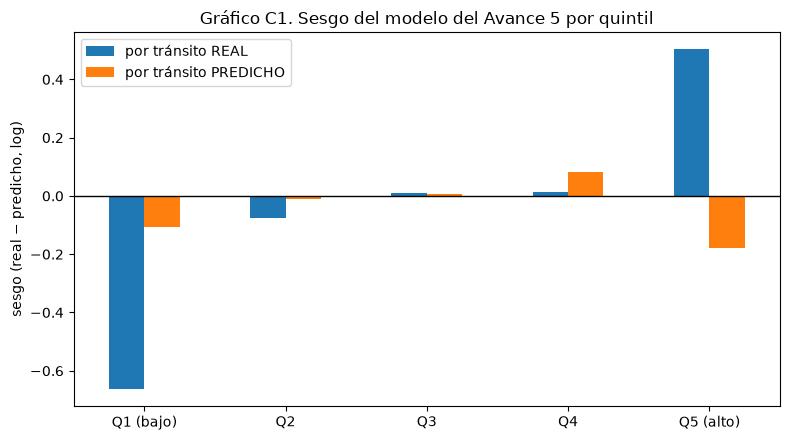

,por tránsito REAL,por tránsito PREDICHO
Q1 (bajo),-0.662,-0.107
Q2,-0.077,-0.009
Q3,0.011,0.005
Q4,0.014,0.081
Q5 (alto),0.503,-0.180


**Lectura.** Agrupando por tránsito real, el quintil más alto se subestima (+0.50) y el más bajo se sobreestima (-0.66). Agrupando por tránsito predicho, el sesgo del quintil más alto es -0.18. La pendiente de predicho frente a real es 0.63 (compresión de extremos) y la del real frente a predicho es 0.99 (cerca de 1). Esto sugiere una calibración lineal global razonable, **pero no elimina la subestimación de los valores reales más altos**, ni garantiza calibración por carretera. Por ello se evalúan correcciones a los datos y modelos, sin asumir que una recalibración lineal sea suficiente.

In [3]:
resid = y - p0
quintil_pred = pd.qcut(p0, 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
sesgos = pd.DataFrame({"por tránsito REAL": resid.groupby(quintil_real).mean(),
                       "por tránsito PREDICHO": resid.groupby(quintil_pred).mean()})
ax = sesgos.plot.bar(figsize=(8, 4.5), rot=0)
ax.axhline(0, color="k", lw=1)
ax.set(title="Gráfico C1. Sesgo del modelo del Avance 5 por quintil", ylabel="sesgo (real − predicho, log)", xlabel="")
plt.tight_layout(); plt.savefig(OUT / "c1_sesgo_real_vs_predicho.png", dpi=120); plt.show()
pend_p_y = np.polyfit(y, p0, 1)[0]      # cuánto sube la predicción cuando el real sube 1
pend_y_p = np.polyfit(p0, y, 1)[0]      # cuánto sube el real cuando la predicción sube 1
display(sesgos.round(3))
display(Markdown(
    f"**Lectura.** Agrupando por tránsito real, el quintil más alto se subestima ({sesgos.iloc[4, 0]:+.2f}) y el más bajo se "
    f"sobreestima ({sesgos.iloc[0, 0]:+.2f}). Agrupando por tránsito predicho, el sesgo del quintil más alto es "
    f"{sesgos.iloc[4, 1]:+.2f}. La pendiente de predicho frente a real es {pend_p_y:.2f} (compresión de extremos) y la del "
    f"real frente a predicho es {pend_y_p:.2f} (cerca de 1). Esto sugiere una calibración lineal global razonable, "
    f"**pero no elimina la subestimación de los valores reales más altos**, ni garantiza calibración por carretera. "
    f"Por ello se evalúan correcciones a los datos y modelos, sin asumir que una recalibración lineal sea suficiente."))

### 1.2 ¿Qué carreteras concentran la subestimación?

In [4]:
d = train.assign(pred=np.exp(p0), resid=resid, flujo_cero=train["red_flujo_paso"] == 0,
                 cuota_sict=train["toll_road"].astype(bool), cuota_rnc=train["fe_peaje"] == 1)
por_carretera = (d.groupby("carretera").agg(sitios=("resid", "size"), tdpa_real_mediana=("tdpa", "median"),
                                            tdpa_predicho_mediana=("pred", "median"), sesgo=("resid", "mean"),
                                            pct_flujo_paso_cero=("flujo_cero", "mean"), cuota_SICT=("cuota_sict", "mean"),
                                            cuota_RNC=("cuota_rnc", "mean"))
                 .query("sitios >= 5").sort_values("sesgo", ascending=False))
display(por_carretera.head(8).style.format({"tdpa_real_mediana": "{:,.0f}", "tdpa_predicho_mediana": "{:,.0f}", "sesgo": "{:+.2f}",
                                            "pct_flujo_paso_cero": "{:.0%}", "cuota_SICT": "{:.0%}", "cuota_RNC": "{:.0%}"}))
inconsistentes = int((train["toll_road"].astype(int) != train["fe_peaje"]).sum())
cuota_mal = int((train["toll_road"].astype(bool) & (train["fe_peaje"] == 0)).sum())
alto = quintil_real == "Q5 (alto)"
print(f"Sitios de entrenamiento donde la cuota de SICT y la de la RNC no coinciden: {inconsistentes} "
      f"({cuota_mal} son de cuota según SICT pero libres según el tramo asignado)")
print(f"Sitios con flujo de paso = 0: {d.flujo_cero.mean():.0%} del total y {d.flujo_cero[alto].mean():.0%} del quintil más alto")

,sitios,tdpa_real_mediana,tdpa_predicho_mediana,sesgo,pct_flujo_paso_cero,cuota_SICT,cuota_RNC
carretera,,,,,,,
México - Querétaro (Cuota),20,"74,583","21,200",+1.39,65%,100%,40%
México - Puebla (Cuota),9,"71,955","37,783",+0.83,56%,100%,78%
Toluca - Palmillas,15,"34,367","16,979",+0.66,80%,0%,33%
Santo Domingo - T. C. (México - Querétaro),5,"10,473","6,721",+0.49,20%,0%,0%
Toluca - Axixintla,5,"12,299","13,727",+0.48,80%,0%,0%
Acapulco - Zihuatanejo,15,"6,988","5,172",+0.44,100%,0%,0%
San Hipólito - Xalapa,12,"12,552","9,908",+0.42,100%,0%,0%
Apizaco - Tejocotal,7,"15,392","9,968",+0.40,100%,0%,0%


Sitios de entrenamiento donde la cuota de SICT y la de la RNC no coinciden: 52 (41 son de cuota según SICT pero libres según el tramo asignado)
Sitios con flujo de paso = 0: 85% del total y 68% del quintil más alto


**Hallazgo a partir de la ejecución.** Entre las carreteras con al menos cinco registros, la subestimación es especialmente elevada en México–Querétaro (Cuota): **+1.39** en log, 20 sitios; México–Puebla (Cuota): **+0.83**, 9 sitios; y Toluca–Palmillas: **+0.66**, 15 sitios. Paralelamente, se observan dos posibles problemas de asignación de variables de entrada:

1. **Inconsistencias de cuota.** Hay **52** sitios del entrenamiento donde `toll_road` (SICT) y `fe_peaje` (RNC) difieren; **41** se identifican como de cuota según SICT, pero como libres según el tramo RNC asociado. Esto es compatible con posibles asociaciones a tramos laterales, enlaces o cuerpos distintos; requiere verificación cartográfica antes de afirmarlo como causa.
2. **Flujo de paso en cero.** `red_flujo_paso = 0` en **85%** de los sitios del entrenamiento y **68%** del quintil de TDPA más alto. Estos ceros pueden deberse a la asignación espacial o a la cobertura de la variable; su presencia no demuestra por sí sola un error del algoritmo.

Las correcciones B y C siguientes son **ajustes a la representación de datos** orientados a evaluar estas hipótesis. La asociación observada no constituye una prueba causal de por qué falla el modelo.

## 2. Correcciones probadas
Todas se evalúan con la misma validación espacial.

- **A. Ponderar los sitios de alto tránsito** al entrenar (`fuerza` 0.5 y 1).
- **B. Corregir la cuota:** si SICT indica que la carretera es de cuota, `fe_peaje = 1`. La cuota es un atributo de la carretera (no del conteo), así que también se conoce en un corredor sin aforos.
- **C. Reparar el flujo de paso:** cada sitio toma el mayor `red_flujo_paso` entre los puntos de su misma carretera a 25 km o menos. Sólo usa variables de entrada, nunca el TDPA. Los 25 km son la distancia a la que desaparece la autocorrelación en el EDA; no se ajustó.
- **B + C** juntas, y **B + C + A**.

In [5]:
RADIO_KM = 25.0

def reparar_flujo(puntos, grupos, radio_km=RADIO_KM):
    # Máximo de red_flujo_paso entre los puntos del mismo grupo (carretera) dentro del radio
    out = puntos["red_flujo_paso"].copy()
    for _, g in puntos.groupby(grupos):
        if len(g) > 1:
            dist = haversine_distances(np.radians(g[["lat", "lon"]].to_numpy(float))) * 6371.0088
            v = g["red_flujo_paso"].to_numpy(float)
            out.loc[g.index] = [v[dist[i] <= radio_km].max() for i in range(len(g))]
    return out

flujo_reparado = reparar_flujo(tabla, tabla["carretera"])
def corregir(datos, cuota=True, flujo=True):
    d = datos.copy()
    if cuota:
        d["fe_peaje"] = np.maximum(d["fe_peaje"], d["toll_road"].astype(int))
    if flujo:
        d["red_flujo_paso"] = flujo_reparado.loc[d.index]
    return d

# nombre -> (corregir cuota, reparar flujo, fuerza de la ponderación)
CONFIG = {"A. Ponderar alto tránsito (0.5)": (False, False, 0.5), "A. Ponderar alto tránsito (1.0)": (False, False, 1.0),
          "B. Cuota corregida": (True, False, 0.0), "C. Flujo de paso reparado": (False, True, 0.0),
          "B + C": (True, True, 0.0), "B + C + A (0.5)": (True, True, 0.5)}
for nombre, (c_cuota, c_flujo, fuerza) in CONFIG.items():
    OOF[nombre] = predecir_cv(corregir(train, cuota=c_cuota, flujo=c_flujo), fuerza=fuerza)

comp = pd.DataFrame({k: resumen(v) for k, v in OOF.items()}).T
comp.to_csv(OUT / "correcciones_alto_transito.csv", encoding="utf-8-sig")
display(comp.style.format({"rmse_log": "{:.4f}", "spearman": "{:.3f}", "acierto_categoria": "{:.1%}", "sesgo_Q5_alto": "{:+.3f}",
                           "rmse_Q5_alto": "{:.3f}", "sesgo_Q1_bajo": "{:+.3f}", "rmse_Q1_bajo": "{:.3f}", "wape_pct": "{:.1f}"}))
print(f"Sitios con flujo de paso > 0: {(train.red_flujo_paso > 0).mean():.0%} -> {(flujo_reparado.loc[train.index] > 0).mean():.0%} tras la reparación")

,rmse_log,spearman,acierto_categoria,sesgo_Q5_alto,rmse_Q5_alto,sesgo_Q1_bajo,rmse_Q1_bajo,wape_pct
Avance 5 (sin cambios),0.6744,0.813,70.6%,+0.503,0.790,-0.662,0.927,48.3
A. Ponderar alto tránsito (0.5),0.6843,0.810,69.4%,+0.411,0.741,-0.697,0.952,49.9
A. Ponderar alto tránsito (1.0),0.6964,0.806,68.8%,+0.362,0.721,-0.730,0.979,51.6
B. Cuota corregida,0.6678,0.817,70.1%,+0.487,0.757,-0.657,0.924,47.9
C. Flujo de paso reparado,0.6597,0.820,69.4%,+0.519,0.754,-0.648,0.908,48.3
B + C,0.6587,0.820,69.8%,+0.513,0.744,-0.644,0.908,48.2
B + C + A (0.5),0.6609,0.820,69.7%,+0.418,0.679,-0.673,0.927,48.7


Sitios con flujo de paso > 0: 15% -> 30% tras la reparación


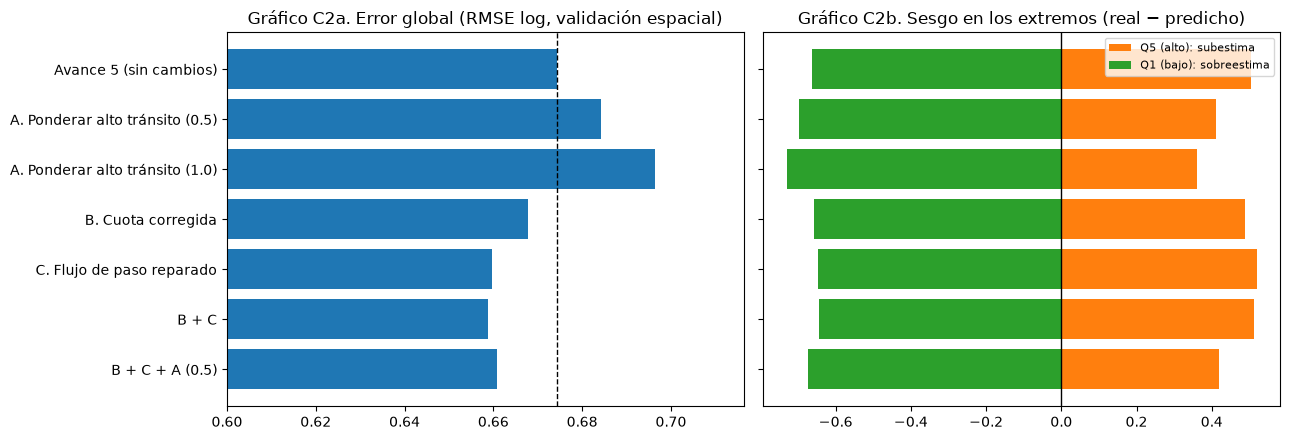

**Corrección de referencia para el Voting: B + C + A (0.5).** Empatadas en RMSE global (±0.005): C. Flujo de paso reparado, B + C, B + C + A (0.5).

- Error global: RMSE log 0.6744 → 0.6609 (2.0% menos); Spearman 0.813 → 0.820.
- Quintil de mayor tránsito: RMSE 0.790 → 0.679 (14% menos); sesgo +0.503 → +0.418.
- Quintil de menor tránsito: sesgo -0.662 → -0.673.

**Lo que no se logró.** El sesgo del quintil alto sigue en +0.42: el modelo todavía predice cerca del 66% del tránsito real en las carreteras más cargadas. Ponderar por sí solo (variantes A) baja ese sesgo pero sube el error global y el sesgo del quintil bajo: mueve el error de un extremo al otro sin agregar información. Las correcciones B y C mejoran el RMSE global, aunque sus cambios de sesgo y error no son uniformes entre todos los quintiles; la combinación B+C+A(0.5) se elige por su balance entre RMSE global y RMSE Q5.

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
orden = comp.index[::-1]
axs[0].barh(orden, comp.loc[orden, "rmse_log"], color="tab:blue"); axs[0].axvline(comp.rmse_log.iloc[0], color="k", ls="--", lw=1)
axs[0].set(title="Gráfico C2a. Error global (RMSE log, validación espacial)", xlim=(0.6, comp.rmse_log.max() + 0.02))
axs[1].barh(orden, comp.loc[orden, "sesgo_Q5_alto"], color="tab:orange", label="Q5 (alto): subestima")
axs[1].barh(orden, comp.loc[orden, "sesgo_Q1_bajo"], color="tab:green", label="Q1 (bajo): sobreestima")
axs[1].axvline(0, color="k", lw=1); axs[1].set(title="Gráfico C2b. Sesgo en los extremos (real − predicho)"); axs[1].set_yticklabels([]); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "c2_correcciones.png", dpi=120); plt.show()

# Regla de decisión (la misma idea del Avance 5): las variantes a menos de 0.005 del mejor RMSE global se consideran
# empatadas; entre ellas se elige la de menor error en el quintil de mayor tránsito, que es el objetivo de esta etapa.
base = comp.iloc[0]
empatadas = comp[comp.rmse_log <= comp.rmse_log.min() + 0.005]
ELEGIDA = empatadas.rmse_Q5_alto.idxmin()
e = comp.loc[ELEGIDA]
display(Markdown(
    f"**Corrección de referencia para el Voting: {ELEGIDA}.** Empatadas en RMSE global (±0.005): {', '.join(empatadas.index)}.\n\n"
    f"- Error global: RMSE log {base.rmse_log:.4f} → {e.rmse_log:.4f} ({100 * (1 - e.rmse_log / base.rmse_log):.1f}% menos); Spearman {base.spearman:.3f} → {e.spearman:.3f}.\n"
    f"- Quintil de mayor tránsito: RMSE {base.rmse_Q5_alto:.3f} → {e.rmse_Q5_alto:.3f} ({100 * (1 - e.rmse_Q5_alto / base.rmse_Q5_alto):.0f}% menos); "
    f"sesgo {base.sesgo_Q5_alto:+.3f} → {e.sesgo_Q5_alto:+.3f}.\n"
    f"- Quintil de menor tránsito: sesgo {base.sesgo_Q1_bajo:+.3f} → {e.sesgo_Q1_bajo:+.3f}.\n\n"
    f"**Lo que no se logró.** El sesgo del quintil alto sigue en {e.sesgo_Q5_alto:+.2f}: el modelo todavía predice cerca del "
    f"{100 * np.exp(-e.sesgo_Q5_alto):.0f}% del tránsito real en las carreteras más cargadas. Ponderar por sí solo (variantes A) baja ese sesgo "
    f"pero sube el error global y el sesgo del quintil bajo: mueve el error de un extremo al otro sin agregar información. "
    f"Las correcciones B y C mejoran el RMSE global, aunque sus cambios de sesgo y error no son uniformes "
    f"entre todos los quintiles; la combinación B+C+A(0.5) se elige por su balance entre RMSE global y RMSE Q5."))

### 2.1 Ensamble seleccionado: LightGBM Raw ponderado (80%) + Voting corregido (20%)

Se evalúa **un único candidato nuevo como modelo final provisional**: LightGBM **sin PCA**, con pérdida cuadrática y ponderación de aforos altos (`fuerza=3`), combinado con el Voting corregido (B + C + A, `fuerza=0.5`). La mezcla 80/20 se realiza sobre las **predicciones de `log(TDPA)`** y no debe confundirse con los pesos de entrenamiento de cada modelo.

- **Datos y protocolo:** `FE_TOP_Model_Table_v2.csv`; 703 registros de entrenamiento, cinco pliegues espaciales con purga. Cada ajuste del preprocesador y los pesos por tránsito se realiza dentro de su respectivo entrenamiento.
- **Representación Raw v2:** variables seguras seleccionadas por `PreparadorSeguro` sin proyectarlas en PCA, junto con las cinco interacciones de red implementadas y ya evaluadas en la receta histórica (flujo, cuota y carriles). No se añaden nuevas características v3.
- **LightGBM:** `n_estimators=350`, `learning_rate=0.035`, `num_leaves=15`, `max_depth=5`, `min_child_samples=25`, `colsample_bytree=0.8`, `reg_lambda=8`, `random_state=20`. Su peso por observación se basa en `1 + 3 × max((log_TDPA − mediana_entreno) / desviación_entreno, 0)`, normalizado a media 1.

**Resultados reproducidos en las salidas de este mismo notebook (CV espacial):**

| Métrica | Voting corregido | **Ensamble 80/20** | Diferencia relevante |
|---|---:|---:|---|
| RMSE log (media de folds) ↓ | 0.6609 | **0.6375** | −3.5% |
| RMSE Q5 (tránsito alto) ↓ | 0.6791 | **0.6218** | −8.4% |
| Sesgo Q5 (`real − predicho`) | +0.4183 | **+0.3894** | Menor subestimación, no eliminada |
| RMSE Q1 (tránsito bajo) ↓ | 0.9273 | **0.9049** | −2.4% |
| Sesgo Q1 | −0.6726 | **−0.6361** | Menor sobreestimación |
| WAPE ↓ | 48.74% | **44.25%** | −4.49 puntos porcentuales |
| Spearman ↑ | 0.8196 | **0.8248** | +0.0052 |
| Acierto de categoría ↑ | **69.7%** | 69.0% | −0.7 puntos porcentuales |

**Interpretación:** el ensamble mejora las principales métricas continuas (RMSE log y WAPE) y el error del quintil Q5, pero **no mejora todas las métricas**: el acierto en categorías baja ligeramente. Estos resultados se obtuvieron con los mismos pliegues empleados para comparar y seleccionar el candidato; no equivalen a una prueba externa independiente.

In [7]:
# Único LightGBM incorporado: referencia Raw ponderada, sin nuevas características v3.
from sklearn.base import TransformerMixin
from sklearn.preprocessing import OneHotEncoder
from lightgbm import LGBMRegressor

PESO_LGB, PESO_VOTING = 0.80, 0.20
FUERZA_LGB, FUERZA_VOTING = 3.0, 0.5
assert abs(PESO_LGB + PESO_VOTING - 1.0) < 1e-12

def interacciones_red_v2(X):
    # Las cinco interacciones previamente probadas (NO son características nuevas v3).
    def numerica(col):
        if col not in X.columns:
            return np.zeros(len(X), dtype=float)
        return (pd.to_numeric(X[col], errors="coerce")
                .replace([np.inf, -np.inf], np.nan).fillna(0).to_numpy(float))
    flujo = np.maximum(numerica("red_flujo_paso"), 0)
    cuota = np.clip(numerica("fe_peaje"), 0, 1)
    carriles = np.maximum(numerica("fe_carriles"), 0)
    return np.column_stack([
        np.log1p(flujo),
        np.log1p(flujo) * cuota,
        np.log1p(flujo) * np.log1p(carriles),
        cuota * np.log1p(carriles),
        (flujo <= 0).astype(float)
    ])

class PreparadorRawV2(BaseEstimator, TransformerMixin):
    """Columnas seguras del Avance 5, sin PCA, y sólo las interacciones históricas v2."""
    def fit(self, X, y=None):
        selector = PreparadorSeguro(modo="Filtro + PCA").fit(X, y)
        requeridas = ("num_seleccionadas_", "cat_seleccionadas_", "pca_cols_")
        if not all(hasattr(selector, a) for a in requeridas):
            raise AttributeError("PreparadorSeguro no expone las listas de variables v2 requeridas")
        prohibidas = {str(TARGET).lower(), "tdpa", "lat", "lon", "km", "carretera", "ctn_id", "toll_road"}
        def permitida(c):
            s = str(c).lower()
            return s not in prohibidas and not any(
                t in s for t in ("tdpa", "aadt", "aforo", "prediccion", "target", "residuo"))
        self.cat_ = list(dict.fromkeys(c for c in selector.cat_seleccionadas_ if permitida(c)))
        self.num_ = list(dict.fromkeys(c for c in
            [*selector.num_seleccionadas_, *selector.pca_cols_]
            if permitida(c) and c not in self.cat_))
        if not (self.num_ or self.cat_):
            raise ValueError("El preparador Raw quedó sin variables permitidas")
        if self.cat_:
            try:
                self.encoder_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
            except TypeError:
                self.encoder_ = OneHotEncoder(handle_unknown="ignore", sparse=False)
            self.encoder_.fit(self._categoricas(X))
        return self

    def _categoricas(self, X):
        return X[self.cat_].astype("string").fillna("__MISSING__").astype(str)

    def transform(self, X):
        faltantes = sorted(set(self.num_ + self.cat_) - set(X.columns))
        if faltantes:
            raise KeyError(f"Variables v2 no disponibles: {faltantes}")
        partes = []
        if self.num_:
            partes.append(X[self.num_].apply(pd.to_numeric, errors="coerce")
                          .replace([np.inf, -np.inf], np.nan).to_numpy(float))
        if self.cat_:
            partes.append(self.encoder_.transform(self._categoricas(X)))
        partes.append(interacciones_red_v2(X))
        return np.hstack(partes)

class LightGBMRawPonderado(BaseEstimator, RegressorMixin):
    """Regresión log(TDPA), pesos de aforos altos calculados dentro de cada fit."""
    def __init__(self, fuerza=3.0):
        self.fuerza = fuerza

    def fit(self, X, y):
        yy = np.asarray(y, dtype=float)
        self.prep_ = PreparadorRawV2()
        Z = self.prep_.fit_transform(X, yy)
        sd = max(float(np.std(yy)), 1e-8)
        pesos = 1.0 + self.fuerza * np.maximum((yy - np.median(yy)) / sd, 0.0)
        pesos = pesos / pesos.mean()
        self.modelo_ = LGBMRegressor(
            n_estimators=350, learning_rate=0.035, num_leaves=15,
            max_depth=5, min_child_samples=25, subsample=0.85,
            subsample_freq=0, colsample_bytree=0.8, reg_lambda=8,
            verbosity=-1, random_state=SEED, n_jobs=THREADS,
            objective="regression"
        )
        self.modelo_.fit(Z, yy, sample_weight=pesos)
        return self

    def predict(self, X):
        pred = np.asarray(self.modelo_.predict(self.prep_.transform(X)), dtype=float)
        if not np.isfinite(pred).all():
            raise ValueError("LightGBM emitió predicciones no finitas")
        return pred

class EnsambleFinal(BaseEstimator, RegressorMixin):
    """80% LightGBM Raw ponderado y 20% Voting B+C+A en log(TDPA)."""
    def fit(self, X, y):
        self.lightgbm_ = LightGBMRawPonderado(FUERZA_LGB).fit(X, y)
        self.voting_ = VotingPonderado(FUERZA_VOTING).fit(X, y)
        return self

    def predict(self, X):
        return (PESO_LGB * self.lightgbm_.predict(X) +
                PESO_VOTING * self.voting_.predict(X))

print("Candidato final: 80% LightGBM Raw ponderado + 20% Voting corregido (en log(TDPA))")

Candidato final: 80% LightGBM Raw ponderado + 20% Voting corregido (en log(TDPA))


Fold espacial 1: 487 entrenamiento, 141 validación
Fold espacial 2: 489 entrenamiento, 145 validación
Fold espacial 3: 394 entrenamiento, 147 validación
Fold espacial 4: 423 entrenamiento, 136 validación
Fold espacial 5: 436 entrenamiento, 134 validación


,rmse_log,spearman,acierto_categoria,sesgo_Q5_alto,rmse_Q5_alto,sesgo_Q1_bajo,rmse_Q1_bajo,wape_pct
Voting corregido (B+C+A 0.5),0.6609,0.8196,69.7%,+0.4183,0.6791,-0.6726,0.9273,48.74%
Ensamble LightGBM Raw 80% + Voting 20%,0.6375,0.8248,69.0%,+0.3894,0.6218,-0.6361,0.9049,44.25%


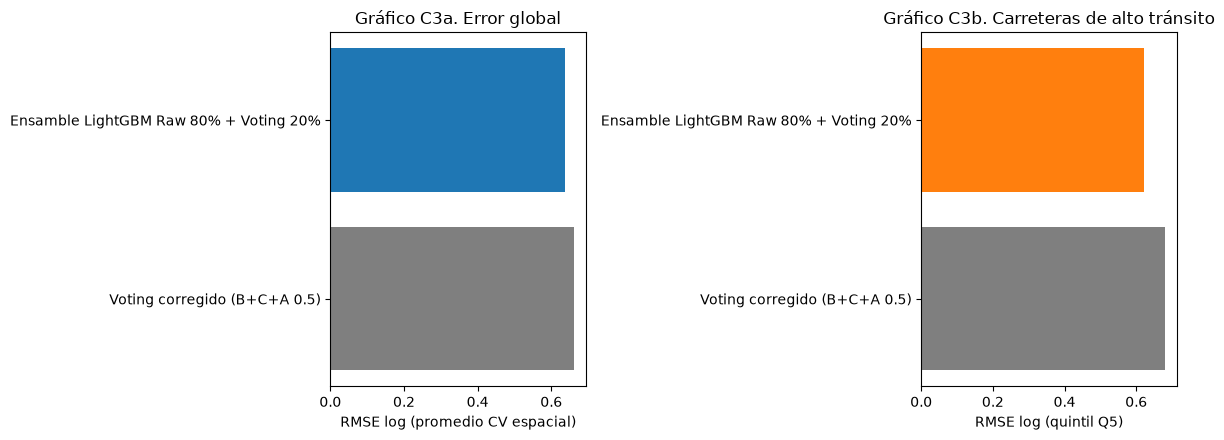

**Mejora observada en esta ejecución.** RMSE global: 0.6609 → 0.6375 (3.5% menos). RMSE Q5: 0.6791 → 0.6218 (8.4% menos). WAPE: 48.74% → 44.25%. **Limitación:** el sesgo Q5 continúa en +0.389, por lo que sigue existiendo subestimación en las carreteras de tránsito más alto.

In [8]:
# Comparación exclusivamente con el Voting corregido que compone el ensamble.
# No se reentrena ni compara ningún otro LightGBM en este notebook.
train_bc = corregir(train, cuota=True, flujo=True)
pred_voting_cv = OOF["B + C + A (0.5)"].astype(float)
pred_lgb_cv = pd.Series(np.nan, index=train.index, dtype=float)
for numero, itr, iva in folds:
    modelo_fold = LightGBMRawPonderado(fuerza=FUERZA_LGB).fit(
        train_bc.loc[itr], train_bc.loc[itr, TARGET])
    pred_lgb_cv.loc[iva] = modelo_fold.predict(train_bc.loc[iva])
    print(f"Fold espacial {numero}: {len(itr)} entrenamiento, {len(iva)} validación")

if pred_lgb_cv.isna().any() or not np.isfinite(pred_lgb_cv).all():
    raise ValueError("Las predicciones OOF del LightGBM están incompletas")
pred_ensamble_cv = PESO_LGB * pred_lgb_cv + PESO_VOTING * pred_voting_cv
comp_ensamble = pd.DataFrame({
    "Voting corregido (B+C+A 0.5)": resumen(pred_voting_cv),
    "Ensamble LightGBM Raw 80% + Voting 20%": resumen(pred_ensamble_cv),
}).T
comp_ensamble.to_csv(OUT / "ensamble_final_validacion_espacial.csv", encoding="utf-8-sig")
display(comp_ensamble.style.format({
    "rmse_log": "{:.4f}", "spearman": "{:.4f}",
    "acierto_categoria": "{:.1%}", "sesgo_Q5_alto": "{:+.4f}",
    "rmse_Q5_alto": "{:.4f}", "sesgo_Q1_bajo": "{:+.4f}",
    "rmse_Q1_bajo": "{:.4f}", "wape_pct": "{:.2f}%"}))

# Control de consistencia frente al experimento anterior (receta v2, sin nuevas características v3).
referencia = {"rmse_log": 0.6375, "rmse_Q5_alto": 0.6218,
              "sesgo_Q5_alto": 0.3894, "rmse_Q1_bajo": 0.9049,
              "wape_pct": 44.2538}
observado = comp_ensamble.loc["Ensamble LightGBM Raw 80% + Voting 20%"]
for metrica, historico in referencia.items():
    tolerancia = 0.02 if metrica == "wape_pct" else 0.005
    if abs(observado[metrica] - historico) > tolerancia:
        print(f"AVISO DE REPRODUCIBILIDAD: {metrica} = {observado[metrica]:.4f} "
              f"(referencia {historico:.4f}); revisar entorno, folds y datos")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
orden = comp_ensamble.index
axs[0].barh(orden, comp_ensamble["rmse_log"], color=["tab:gray", "tab:blue"])
axs[0].set(xlabel="RMSE log (promedio CV espacial)", title="Gráfico C3a. Error global")
axs[1].barh(orden, comp_ensamble["rmse_Q5_alto"], color=["tab:gray", "tab:orange"])
axs[1].set(xlabel="RMSE log (quintil Q5)", title="Gráfico C3b. Carreteras de alto tránsito")
plt.tight_layout()
plt.savefig(OUT / "c3_ensamble_final_cv.png", dpi=120)
plt.show()

b, f = comp_ensamble.iloc[0], comp_ensamble.iloc[1]
display(Markdown(
    f"**Mejora observada en esta ejecución.** RMSE global: {b.rmse_log:.4f} → {f.rmse_log:.4f} "
    f"({100 * (1 - f.rmse_log / b.rmse_log):.1f}% menos). "
    f"RMSE Q5: {b.rmse_Q5_alto:.4f} → {f.rmse_Q5_alto:.4f} "
    f"({100 * (1 - f.rmse_Q5_alto / b.rmse_Q5_alto):.1f}% menos). "
    f"WAPE: {b.wape_pct:.2f}% → {f.wape_pct:.2f}%. "
    f"**Limitación:** el sesgo Q5 continúa en {f.sesgo_Q5_alto:+.3f}, "
    f"por lo que sigue existiendo subestimación en las carreteras de tránsito más alto."
))

**Criterio de adopción provisional.** Se adopta el ensamble 80/20 porque, **en la ejecución espacial actual**, mejora el RMSE log global (**0.6609 → 0.6375**), el RMSE Q5 (**0.6791 → 0.6218**) y el WAPE (**48.74% → 44.25%**) respecto del Voting corregido. También disminuye el RMSE Q1 (**0.9273 → 0.9049**), por lo que no empeora ese extremo en la métrica utilizada.

**Compensaciones y limitaciones:** el acierto por categorías desciende de **69.7% a 69.0%**; el sesgo Q5 aún es **+0.3894** en log, lo que indica subestimación persistente en el tramo superior de TDPA real. El WAPE de **44.25%** sigue siendo considerable: el modelo estima TDPA, pero **no sustituye un aforo medido**. Los quintiles Q1 y Q5 se forman con el TDPA real **solamente para evaluar**, no para clasificar un sitio nuevo cuyo tránsito se desconoce.

La corrección espacial B+C a 25 km se conserva como en el cierre original; su transferibilidad a otros corredores sigue pendiente. No se afirma que la mezcla 80/20 sea óptima frente a todas las opciones posibles.

### 2.2 Diagnóstico en el corredor MEX-095D

Se comparan el Avance 5, el Voting corregido B+C+A y **únicamente el ensamble final 80/20**, utilizando los **23 aforos** apartados del corredor. La tabla y el gráfico siguientes **ya fueron ejecutados**:

| Métrica | Avance 5 | Voting corregido | **Ensamble 80/20** |
|---|---:|---:|---:|
| RMSE log ↓ | 0.6528 | 0.6037 | **0.5913** |
| Sesgo (`real − predicho`; ideal 0) | +0.2795 | **+0.0889** | +0.1431 |
| Spearman ↑ | 0.6275 | 0.6067 | **0.6453** |
| Acierto de categoría ↑ | 69.6% | 69.6% | 69.6% |

**Lectura:** el ensamble tiene el menor RMSE y la mejor correlación de rangos en este corredor; sin embargo, **su sesgo medio positivo es mayor que el del Voting corregido** (+0.1431 frente a +0.0889), y el acierto categórico no cambia. En la referencia experimental anterior se había reportado además WAPE de **44.98%** para el ensamble frente a **42.28%** para Voting; ese indicador **no se recalcula en la tabla siguiente**, por lo que se distingue de las métricas ahora visibles.

El corredor ya se analizó en avances previos; se utiliza como **diagnóstico complementario y no como validación independiente de la selección 80/20**. Las predicciones que se usarán en las secciones 3 y 4 sí corresponden al nuevo ensamble.

,rmse_log,sesgo,spearman,acierto_categoria
Avance 5,0.6528,+0.2795,0.6275,69.6%
Voting corregido B+C+A,0.6037,+0.0889,0.6067,69.6%
Ensamble final 80/20,0.5913,+0.1431,0.6453,69.6%


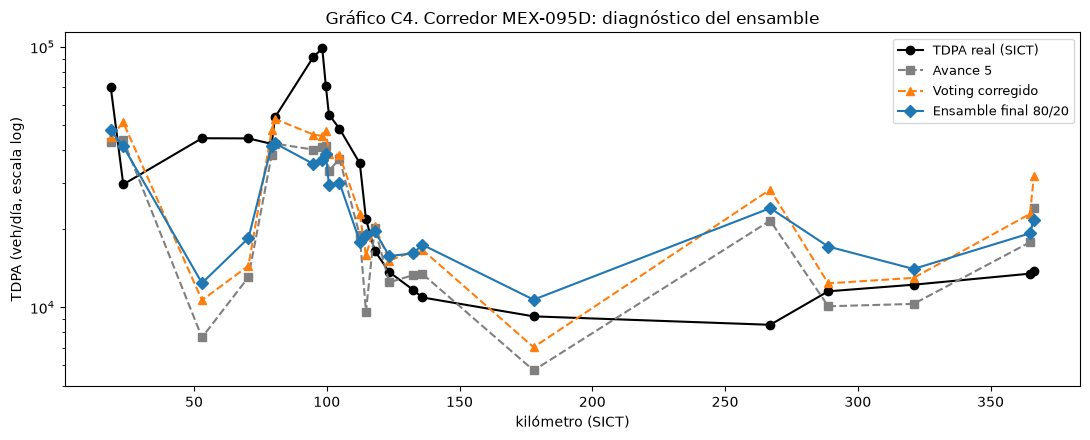

In [9]:
# Diagnóstico en el corredor: no interviene en la elección de pesos ni del modelo.
T = test.sort_values("KM")
yT, km = T[TARGET].to_numpy(float), T["KM"].to_numpy(float)
test_bc = corregir(T, cuota=True, flujo=True)
modelo_a5 = VotingPonderado().fit(train, y)
modelo_corr = VotingPonderado(FUERZA_VOTING).fit(train_bc, y)
modelo_final = EnsambleFinal().fit(train_bc, y)
pT0 = modelo_a5.predict(T)
pT_voting = modelo_corr.predict(test_bc)
pT1 = modelo_final.predict(test_bc)   # Usado también en sección 3.

def m_ext(p):
    r = yT - p
    return {"rmse_log": np.sqrt((r ** 2).mean()), "sesgo": r.mean(),
            "spearman": spearmanr(yT, p)[0],
            "acierto_categoria": float(np.mean(
                np.digitize(T["tdpa"], CORTES) == np.digitize(np.exp(p), CORTES)))}

ext = pd.DataFrame({
    "Avance 5": m_ext(pT0),
    "Voting corregido B+C+A": m_ext(pT_voting),
    "Ensamble final 80/20": m_ext(pT1)
}).T
ext.to_csv(OUT / "diagnostico_corredor_ensamble_final.csv", encoding="utf-8-sig")
display(ext.style.format({"rmse_log": "{:.4f}", "sesgo": "{:+.4f}",
                          "spearman": "{:.4f}", "acierto_categoria": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(km, T["tdpa"], "o-", color="black", label="TDPA real (SICT)")
ax.plot(km, np.exp(pT0), "s--", color="gray", label="Avance 5")
ax.plot(km, np.exp(pT_voting), "^--", color="tab:orange", label="Voting corregido")
ax.plot(km, np.exp(pT1), "D-", color="tab:blue", label="Ensamble final 80/20")
ax.set_yscale("log")
ax.set(xlabel="kilómetro (SICT)", ylabel="TDPA (veh/día, escala log)",
       title="Gráfico C4. Corredor MEX-095D: diagnóstico del ensamble")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "c4_corredor_ensamble_final.png", dpi=120)
plt.show()

## 3. ¿Cuánto vale el ensamble cuando hay pocos aforos o ninguno?

Para estudiar el uso en corredores poco instrumentados se mantiene la simulación del cierre anterior, **ejecutada ahora con el ensamble 80/20**. Se seleccionan aleatoriamente *k* de los 23 aforos del corredor como disponibles (300 repeticiones por valor de *k*) y se predice el TDPA de los demás con: (i) interpolación entre aforos, (ii) modelo territorial sin utilizar aforos locales para entrenarse y (iii) combinación de ambos con peso `exp(−distancia_al_aforo_más_cercano / 80 km)`. Para *k* = 0, el ensamble se compara con una referencia calculada por tipo de vía y cuota.

**Resultados observados en esta ejecución:** sin aforos, el ensamble logra **RMSE log ≈ 0.59** frente a **≈ 0.87** del baseline (reducción de **≈ 32%**). Con **2 y 3 aforos** resulta mejor el modelo solo que la interpolación (por ejemplo, con 3 aforos: **0.592 vs. 0.714**). Con **3, 4 y 6 aforos**, la combinación obtiene el menor error de las tres opciones (con 4: **0.507**, frente a **0.578** de interpolación y **0.591** del modelo). Para los valores evaluados desde **8 hasta 20 aforos**, la interpolación presenta el menor error, aunque a 8 es casi un empate con la combinación (**0.360 vs. 0.362**).

La simulación se realiza sobre **un único corredor y sus 23 puntos conocidos**; no prueba que estos umbrales de número de aforos se repitan en otras carreteras. Los valores calculados en la siguiente celda se conservan como evidencia de la ejecución, en lugar de reutilizar resultados anteriores del Voting.

,km_por_aforo,interpolación,modelo,combinación
aforos_disponibles,,,,
2,174,0.832,0.592,0.612
3,116,0.714,0.592,0.572
4,87,0.578,0.591,0.507
6,58,0.439,0.593,0.418
8,43,0.360,0.594,0.362
12,29,0.289,0.594,0.309
16,22,0.265,0.579,0.285
20,17,0.232,0.547,0.252


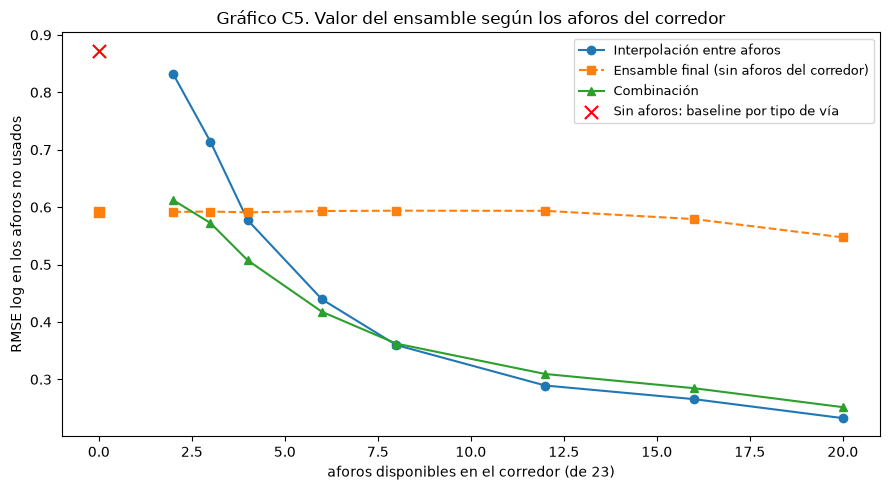

**Resultado para el ensamble.** Sin ningún aforo, el modelo tiene un RMSE log de 0.59 contra 0.87 del baseline (32% menos error). El modelo solo supera a la interpolación mientras el corredor tenga 3 aforos o menos (un aforo cada 116 km o más espaciados). La combinación es la mejor opción con entre 3 y 6 aforos. Con más aforos, interpolar es suficiente.

**Por lo tanto, el valor del modelo está en los corredores sin aforos o con aforos muy espaciados**, y en los huecos largos de un corredor que sí los tiene (como los km 180–220 de la MEX-095D). Donde hay aforos cercanos, el modelo sólo complementa.

In [10]:
# k = 0: baseline contra modelo
medias = y.groupby([train["road_tipo_vial"], train["fe_peaje"]]).mean()
p_base = medias.reindex(pd.MultiIndex.from_frame(T[["road_tipo_vial", "fe_peaje"]])).fillna(y.mean()).to_numpy()
rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
SIN_AFOROS = {"baseline": rmse(yT, p_base), "modelo": rmse(yT, pT1)}

rng = np.random.default_rng(SEED)
L_KM, REPS, filas = 80.0, 300, []
for k in [2, 3, 4, 6, 8, 12, 16, 20]:
    err = {"interpolación": [], "modelo": [], "combinación": []}
    for _ in range(REPS):
        disp = np.sort(rng.choice(len(T), k, replace=False))
        fuera = np.setdiff1d(np.arange(len(T)), disp)
        interp = np.interp(km[fuera], km[disp], yT[disp])
        w = np.exp(-np.abs(km[fuera][:, None] - km[disp][None, :]).min(axis=1) / L_KM)
        err["interpolación"].append(rmse(yT[fuera], interp)); err["modelo"].append(rmse(yT[fuera], pT1[fuera]))
        err["combinación"].append(rmse(yT[fuera], w * interp + (1 - w) * pT1[fuera]))
    filas.append({"aforos_disponibles": k, "km_por_aforo": round((km.max() - km.min()) / k), **{a: np.mean(b) for a, b in err.items()}})
curva = pd.DataFrame(filas).set_index("aforos_disponibles")
curva.to_csv(OUT / "valor_sin_aforos.csv", encoding="utf-8-sig")
display(curva.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curva.index, curva["interpolación"], "o-", label="Interpolación entre aforos")
ax.plot(curva.index, curva["modelo"], "s--", label="Ensamble final (sin aforos del corredor)")
ax.plot(curva.index, curva["combinación"], "^-", label="Combinación")
ax.scatter([0], [SIN_AFOROS["baseline"]], marker="x", s=90, color="red", zorder=5, label="Sin aforos: baseline por tipo de vía")
ax.scatter([0], [SIN_AFOROS["modelo"]], marker="s", s=60, color="tab:orange", zorder=5)
ax.set(xlabel="aforos disponibles en el corredor (de 23)", ylabel="RMSE log en los aforos no usados",
       title="Gráfico C5. Valor del ensamble según los aforos del corredor")
ax.legend(fontsize=9); plt.tight_layout(); plt.savefig(OUT / "c4_valor_sin_aforos.png", dpi=120); plt.show()

gana_modelo = curva.index[curva["modelo"] < curva["interpolación"]]
gana_combo = curva.index[curva["combinación"] <= curva[["interpolación", "modelo"]].min(axis=1)]
k_m = int(gana_modelo.max()) if len(gana_modelo) else 0
k_c = f"entre {int(gana_combo.min())} y {int(gana_combo.max())}" if len(gana_combo) else "ningún número de"
display(Markdown(
    f"**Resultado para el ensamble.** Sin ningún aforo, el modelo tiene un RMSE log de {SIN_AFOROS['modelo']:.2f} contra {SIN_AFOROS['baseline']:.2f} del baseline "
    f"({100 * (1 - SIN_AFOROS['modelo'] / SIN_AFOROS['baseline']):.0f}% menos error). El modelo solo supera a la interpolación mientras el corredor "
    f"tenga {k_m} aforos o menos (un aforo cada {curva.loc[k_m, 'km_por_aforo'] if k_m else '—'} km o más espaciados). La combinación es la mejor "
    f"opción con {k_c} aforos. Con más aforos, interpolar es suficiente.\n\n"
    f"**Por lo tanto, el valor del modelo está en los corredores sin aforos o con aforos muy espaciados**, y en los huecos largos de un corredor "
    f"que sí los tiene (como los km 180–220 de la MEX-095D). Donde hay aforos cercanos, el modelo sólo complementa."))

## 4. Estimaciones con el ensamble final para los CTN

La sección CTN **ya se ejecutó** con el ensamble 80/20. Se conserva la preparación B+C del cierre: se **supone** que todos los CTN son de cuota (`fe_peaje=1`) y se repara `red_flujo_paso` a partir de CTN y puntos del corredor dentro de **25 km**. En los datos originales había **4 CTN con `fe_peaje=0`** y **5 con flujo de paso en cero**; después de la reparación aplicada, el segundo conteo quedó en **0**. Son supuestos de atributos geoespaciales y **deben contrastarse** con el trazado real.

**Resultados de las predicciones guardadas:** el TDPA estimado por el ensamble es **34.0% mayor en la mediana** que el del Voting corregido. Algunos cambios individuales son sustanciales: `CTN_007` pasa de **19,010** a **44,624** veh/día (**+134.7%**); `CTN_009`, de **39,099** a **83,538** (**+113.7%**); y `CTN_021`, de **6,416** a **11,776** (**+83.5%**). La celda muestra los ocho casos con mayor cambio relativo absoluto y guarda el CSV correspondiente.

**Advertencia:** una predicción mayor **no significa automáticamente mayor exactitud**. En este archivo **no hay TDPA observado para los CTN** con el cual contrastar los aumentos; por ello, las estimaciones no deben interpretarse como aforos verificados ni utilizarse directamente para dimensionar infraestructura sin revisar las variables y el corredor. Se conservan las columnas del Avance 5 y Voting para trazabilidad; no se sobrescribe su archivo histórico, no se añaden intervalos ni procedimientos v3.

In [11]:
# La versión operativa CTN se obtiene del ensamble, NO del Voting corregido.
ctn = pd.read_csv(TABLA_CTN, low_memory=False)
ctn_c = ctn.copy()
ctn_c["fe_peaje"] = 1      # Hipótesis ya utilizada en el cierre: verificar para cada CTN.
pts = pd.concat([
    ctn[["lat", "lon", "red_flujo_paso"]].reset_index(drop=True),
    T[["lat", "lon", "red_flujo_paso"]].reset_index(drop=True)
], ignore_index=True)
ctn_c["red_flujo_paso"] = reparar_flujo(
    pts, np.zeros(len(pts), dtype=int)).iloc[:len(ctn)].to_numpy()

salida = pd.DataFrame({
    "ctn_id": ctn["ctn_id"],
    "chainage_km": ctn["chainage_km"],
    "tdpa_avance5": np.exp(modelo_a5.predict(ctn)).round(0),
    "tdpa_voting_corregido": np.exp(modelo_corr.predict(ctn_c)).round(0),
    "tdpa_ensamble_final": np.exp(modelo_final.predict(ctn_c)).round(0)
})
salida["cambio_ensamble_vs_avance5_pct"] = (
    100 * (salida.tdpa_ensamble_final / salida.tdpa_avance5 - 1)).round(1)
salida["cambio_ensamble_vs_voting_pct"] = (
    100 * (salida.tdpa_ensamble_final / salida.tdpa_voting_corregido - 1)).round(1)
salida.to_csv(OUT / "predicciones_ctn_ensamble_final.csv", index=False, encoding="utf-8-sig")
print(f"CTN con fe_peaje = 0 originalmente: {(ctn.fe_peaje == 0).sum()} | "
      f"flujo de paso = 0: {(ctn.red_flujo_paso == 0).sum()} -> "
      f"{(ctn_c.red_flujo_paso == 0).sum()} después de reparar")
print(f"Cambio mediano vs Voting corregido: {salida.cambio_ensamble_vs_voting_pct.median():+.1f}%")
display(salida.reindex(
    salida.cambio_ensamble_vs_voting_pct.abs().sort_values(ascending=False).index).head(8))

CTN con fe_peaje = 0 originalmente: 4 | flujo de paso = 0: 5 -> 0 después de reparar
Cambio mediano vs Voting corregido: +34.0%


,ctn_id,chainage_km,tdpa_avance5,tdpa_voting_corregido,tdpa_ensamble_final,cambio_ensamble_vs_avance5_pct,cambio_ensamble_vs_voting_pct
7,CTN_007,50.000,15835.0,19010.0,44624.0,181.8,134.7
9,CTN_009,70.000,23326.0,39099.0,83538.0,258.1,113.7
21,CTN_021,150.000,5345.0,6416.0,11776.0,120.3,83.5
3,CTN_003,20.000,21190.0,29258.0,53546.0,152.7,83.0
6,CTN_006,40.000,24303.0,28542.0,51857.0,113.4,81.7
5,CTN_005,36.574,29011.0,34022.0,61523.0,112.1,80.8
4,CTN_004,30.000,16507.0,22704.0,39778.0,141.0,75.2
2,CTN_002,10.000,38680.0,48824.0,83536.0,116.0,71.1


## 5. Conclusiones

**Diagnóstico y correcciones originales**
- El Voting del Avance 5 presenta compresión hacia valores intermedios: cuando la evaluación agrupa por **TDPA real**, el sesgo Q5 es **+0.5033** y el Q1 es **−0.6625**. Agrupar por TDPA predicho puede mostrar otra tendencia y no resuelve por sí solo la subestimación de los extremos reales.
- Se observaron **52 discrepancias** entre los indicadores de cuota y **85%** de sitios con flujo de paso en cero. Estas inconsistencias justifican revisar la asignación territorial, pero no demuestran una causa única del error. La reparación B+C más ponderación A=0.5 se utiliza en el Voting corregido, sin confundir su `fuerza=0.5` con la ponderación `fuerza=3` del LightGBM.

**Rendimiento del modelo final provisional: ensamble 80/20**
- Con la validación espacial guardada, el ensamble mejora frente al Voting corregido: **RMSE log 0.6609 → 0.6375 (−3.5%)**, **RMSE Q5 0.6791 → 0.6218 (−8.4%)**, **RMSE Q1 0.9273 → 0.9049 (−2.4%)** y **WAPE 48.74% → 44.25% (−4.49 puntos porcentuales)**. Spearman aumenta de **0.8196 a 0.8248**.
- **Hay compromisos:** el acierto por categoría baja de **69.7% a 69.0%**, el sesgo Q5 sigue siendo **+0.3894** y el WAPE global permanece elevado. La mezcla se selecciona por el compromiso entre error global y tránsito alto, no porque gane todas las métricas.
- En **MEX-095D (23 aforos)**, el ensamble alcanzó **RMSE 0.5913** frente a **0.6037** del Voting corregido y **0.6528** del Avance 5. El sesgo, sin embargo, aumentó frente al Voting corregido (**+0.1431** vs. **+0.0889**). El corredor ya se había utilizado como diagnóstico, por lo que este resultado **no es una validación nueva independiente**.

**Valor cuando escasean aforos y estimaciones CTN**
- En la simulación de la sección 3, sin aforos el ensamble logró **RMSE ≈ 0.59** vs. **≈ 0.87** de la referencia por tipo de vía; para **2–3 aforos** superó a la interpolación, y la **combinación** fue mejor para **3, 4 y 6 aforos**. A partir de 8 aforos (entre los valores estudiados), la interpolación obtuvo menor error. **Son umbrales observados sólo en este corredor**, no una regla universal.
- Las **estimaciones CTN sí se calcularon**: el cambio mediano del ensamble frente al Voting corregido es **+34.0%**, con diferencias superiores al **100%** en algunos sitios. Como no hay aforos reales CTN en esta evaluación, **no puede afirmarse que estos incrementos sean correcciones acertadas**. Es prioritario verificar la hipótesis de cuota y la asignación del flujo antes de utilizarlas operativamente.
- **Estado del avance:** el ensamble 80/20 se presenta como **modelo final provisional** de la tabla v2. Quedan pendientes una validación genuinamente independiente en otros corredores, el análisis de incertidumbre y las modificaciones a la ingeniería de características. Los experimentos con otros modelos y los procesos nuevos de v3 **se mantienen fuera de este notebook**.

## 6. Contribución individual

| Integrante | Contribución en esta etapa | Contribución en el proyecto |
|---|---|---|
| Ana Karen Estupiñán | Corrección de los datos asociados al alto tránsito, evaluación de alternativas y elaboración de resultados para el cierre; desarrollo de la caracterización de los CTN. | Desarrollo del modelado y validación espacial; incorporación de variables de red vial y uso de suelo; integración de fuentes y caracterización de los CTN con datos públicos. |
| Quirec | Experimentos con ensambles y apoyo a las correcciones finales; comparación de resultados en el corredor y en escenarios con pocos o ningún aforo. | Desarrollo y ejecución de notebooks de avances anteriores, preparación de datos y características, comparación de modelos y experimentación con ensambles. |
| Andrea Carolina Flores Ramírez | Revisión y mejora de la comparación de modelos del Avance 4, incluida la evaluación externa y la actualización de métricas y resultados. | Integración de aforos SICT 2025 y análisis exploratorio; preparación de datos y mejora de variables para el modelado en avances anteriores. |

## Declaración sobre el uso de herramientas de inteligencia artificial

Se utilizó Claude (Anthropic) como apoyo para diagnosticar la subestimación en carreteras de alto tránsito, proponer y programar las correcciones y el experimento de aforos disponibles, y redactar borradores de las interpretaciones. El equipo es responsable de revisar, ejecutar, interpretar y validar el código, los resultados y las conclusiones antes de la entrega.

**Nota sobre esta actualización:** Se utilizó ChatGPT (OpenAI) como apoyo para integrar el ensamble LightGBM Raw ponderado + Voting corregido, reorganizar la comparación de modelos y ajustar los textos interpretativos. La validación final de las ejecuciones, cifras y afirmaciones corresponde al equipo.
